In [17]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             ConfusionMatrixDisplay, classification_report)

FEATS  = "features_r21d_s3d.npy"  # features.npy / features_ft.npy / features_r21d.npy

df = pd.read_csv("index.csv")
feats = np.load(FEATS)
print(FEATS, feats.shape)

X = feats.mean(axis=1) if feats.ndim == 3 else feats   # кадровые признаки усредняем по времени
y = df.label.values                                    # 0 = eat, 1 = drink
tv = (df.split != "test").values                       # train + val
X_tv, y_tv, g_tv = X[tv], y[tv], df.source[tv].values
X_te, y_te = X[~tv], y[~tv]
print(X_tv.shape, X_te.shape)

features_r21d_s3d.npy (272, 1536)
(192, 1536) (80, 1536)


In [18]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

candidates = {
    "Dummy (majority)": (DummyClassifier(strategy="most_frequent"), {}),
    "LogReg": (LogisticRegression(max_iter=5000, class_weight="balanced"),
               {"clf__C": [0.001, 0.01, 0.1, 1]}),
    "SVM linear": (SVC(kernel="linear", class_weight="balanced"),
                   {"clf__C": [0.001, 0.01, 0.1, 1]}),
    "SVM rbf": (SVC(kernel="rbf", class_weight="balanced"),
                {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 1e-3, 1e-4]}),
}

rows, models = [], {}
for name, (est, grid) in candidates.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", est)])   # масштабирование + классификатор
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="balanced_accuracy")
    gs.fit(X_tv, y_tv, groups=g_tv)       # после подбора дообучается на всём train+val
    pred = gs.predict(X_te)
    models[name] = gs.best_estimator_
    rows.append({"model": name, "params": gs.best_params_,
                 "cv_bal_acc": gs.best_score_,
                 "test_acc": accuracy_score(y_te, pred),
                 "test_bal_acc": balanced_accuracy_score(y_te, pred),
                 "test_f1_macro": f1_score(y_te, pred, average="macro")})

res = pd.DataFrame(rows).round(3)
res.to_csv("results_svm.csv", index=False)
res

,model,params,cv_bal_acc,test_acc,test_bal_acc,test_f1_macro
0,Dummy (majority),{},0.500,0.575,0.500,0.365
1,LogReg,{'clf__C': 0.01},0.695,0.875,0.868,0.871
2,SVM linear,{'clf__C': 0.001},0.714,0.875,0.868,0.871
3,SVM rbf,"{'clf__C': 1, 'clf__gamma': 0.0001}",0.703,0.788,0.792,0.786


SVM linear
              precision    recall  f1-score   support

         eat       0.88      0.82      0.85        34
       drink       0.88      0.91      0.89        46

    accuracy                           0.88        80
   macro avg       0.88      0.87      0.87        80
weighted avg       0.88      0.88      0.87        80



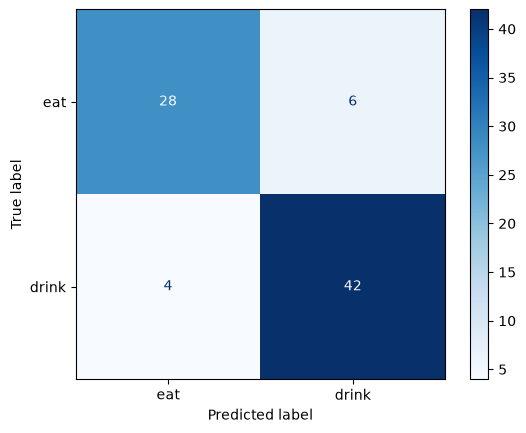

In [19]:
best = res.iloc[1:].sort_values("cv_bal_acc").iloc[-1].model   # выбор по CV, не по test
pred = models[best].predict(X_te)
print(best)
print(classification_report(y_te, pred, target_names=["eat", "drink"]))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["eat", "drink"], cmap="Blues");

/home/ekaterina/OP/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
7 fits failed out of a total of 25.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
7 fits failed with the following error:
Traceback (most recent call last):
  File "/home/ekaterina/OP/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 860, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/ekaterina/OP/venv/lib/python3.12/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ekaterina/OP/venv/lib/python3.12/site-packages/sklearn/pipeline.py", line 645

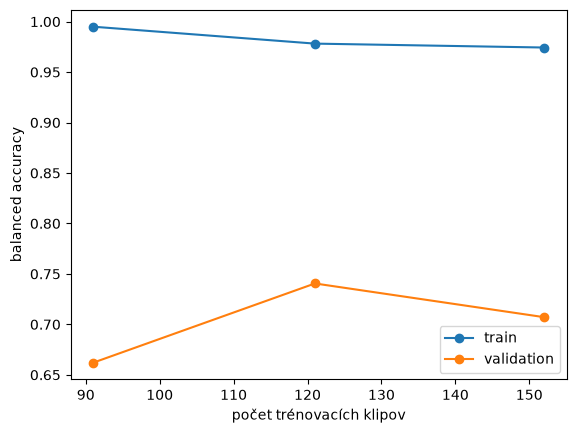

In [20]:
from sklearn.model_selection import learning_curve
from matplotlib import pyplot as plt

sizes, tr, va = learning_curve(models[best], X_tv, y_tv, groups=g_tv, cv=cv,
                               scoring="balanced_accuracy", train_sizes=np.linspace(0.2, 1, 5))
plt.plot(sizes, tr.mean(1), "o-", label="train")
plt.plot(sizes, va.mean(1), "o-", label="validation")
plt.xlabel("počet trénovacích klipov"); plt.ylabel("balanced accuracy"); plt.legend(); plt.show()

In [21]:
def wrong_eat(feats_file):
    F = np.load(feats_file)
    X_ = F.mean(axis=1) if F.ndim == 3 else F
    m = Pipeline([("scaler", StandardScaler()),
                  ("clf", SVC(kernel="linear", class_weight="balanced", C=0.01))])
    m.fit(X_[tv], y[tv])
    p = m.predict(X_[~tv])
    return set(df[~tv].path[(y_te == 0) & (p == 1)])

a, b = wrong_eat("features_r21d.npy"), wrong_eat("features_s3d.npy")
print(len(a), len(b), "общих:", len(a & b))
for path in sorted(a & b):
    print(path)

13 11 общих: 3
HMDB51/eat/APOCALYPTO_eat_u_nm_np1_fr_goo_6
HMDB51/eat/RETURN_OF_THE_KING_eat_h_nm_np1_le_goo_19
HMDB51/eat/RETURN_OF_THE_KING_eat_h_nm_np1_ri_bad_17


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

def eval_repeated(feats_file, seeds=range(10)):
    F = np.load(feats_file)
    X_ = F.mean(axis=1) if F.ndim == 3 else F
    scores = []
    for s in seeds:
        gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=s)
        tr_idx, te_idx = next(gss.split(X_, y, groups=df.source))
        gs = GridSearchCV(
            Pipeline([("scaler", StandardScaler()),
                      ("clf", SVC(kernel="linear", class_weight="balanced"))]),
            {"clf__C": [0.001, 0.01, 0.1, 1]},
            cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0),
            scoring="balanced_accuracy")
        gs.fit(X_[tr_idx], y[tr_idx], groups=df.source.values[tr_idx])
        scores.append(balanced_accuracy_score(y[te_idx], gs.predict(X_[te_idx])))
    return np.mean(scores), np.std(scores)

for f in ["features.npy", "features_r21d.npy", "features_s3d.npy", "features_r21d_s3d.npy"]:
    m, sd = eval_repeated(f)
    print(f"{f:25s} {m:.3f} ± {sd:.3f}")


features.npy              0.624 ± 0.066
features_r21d.npy         0.795 ± 0.024
features_s3d.npy          0.721 ± 0.049
features_r21d_s3d.npy     0.765 ± 0.058


In [23]:
for f in ["features_r21d.npy", "features_r21d_s3d.npy"]:
    print(f, np.round(eval_repeated(f), 2))

features_r21d.npy [0.8  0.02]
features_r21d_s3d.npy [0.77 0.06]
